# 3. Classical baselines

LR, RF and XGBoost use 58 time-domain features with fixed settings. LOSO holds out one subject per fold; scaling uses training subjects only. Primary metric: mean subject-level macro F1 across 12 activities, with absent classes scored zero.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / 'har_utils.py').exists() and (p / 'comparison_utils.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Project root not found.')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, str(ROOT))
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from har_utils import SEED, LABELS, ACTIVITIES, feature_columns, models
from comparison_utils import (OUT, prepare_windows, validate_windows,
                              run_baseline, load_baseline, neural_diagnostic,
                              boosting_diagnostic, comparison_models as models)
OUT.mkdir(parents=True, exist_ok=True)
FIGURES = OUT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

SELECTED_MODELS = os.environ.get('HAR_MODELS', 'LR,RF,XGBoost,MLP').split(',')


## Cached features


In [2]:
REBUILD_WINDOWS = False
FORCE_RETRAIN = False
DURATIONS = (1, 2)
datasets = {s: prepare_windows(s, rebuild=REBUILD_WINDOWS) for s in DURATIONS}
for s, (X, meta) in datasets.items():
    validate_windows(X, meta)
    print(f'{s}s: {len(meta):,} windows; {len(feature_columns(X))} time features; '
          f'{meta.subject.nunique()} subjects; mixed={(meta.purity < 1).mean():.2%}')
assert set(datasets[1][1].subject) == set(datasets[2][1].subject)
assert feature_columns(datasets[1][0]) == feature_columns(datasets[2][0])
baseline_models = {k: v for k, v in models().items() if k in SELECTED_MODELS}
environment = {'python': sys.version, 'packages': {p: importlib.metadata.version(p)
               for p in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'xgboost']}}
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2))
display(pd.Series({k: str(v) for k, v in baseline_models.items()}, name='fixed model'))


1s: 120,765 windows; 58 time features; 21 subjects; mixed=4.53%
2s: 60,214 windows; 58 time features; 21 subjects; mixed=8.06%


LR         Pipeline(steps=[('standardscaler', StandardSca...
RF         RandomForestClassifier(max_depth=20, min_sampl...
XGBoost    XGBClassifier(base_score=None, booster=None, c...
Name: fixed model, dtype: str

## Included subjects

21 usable subjects. S006 is excluded because its 10 ms cadence differs from the 20 ms windowing rule.


## Duration audit

Both durations use identical subject splits; window counts, majority labels and purity may differ.


,window_seconds,windows,subjects,mixed_fraction,mean_purity,used_samples,discarded_samples
0,1,120765,21,0.045270,0.987716,6038250,423078
1,2,60214,21,0.080612,0.977210,6021400,439928


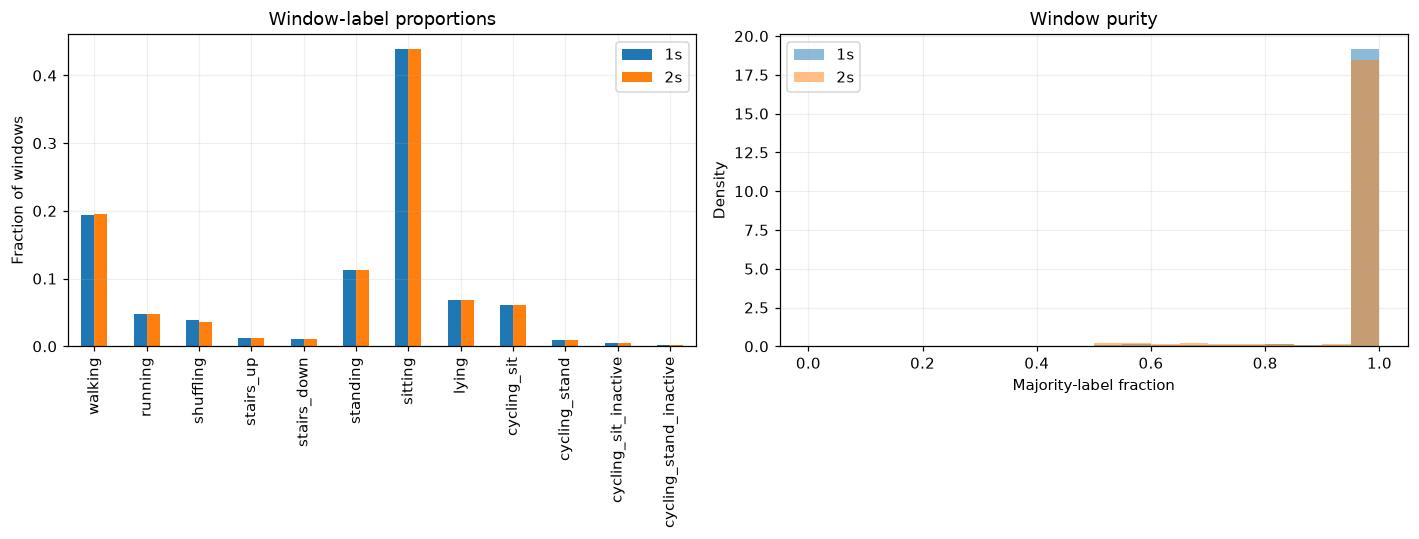

In [3]:
audit_rows = []
for s, (_, meta) in datasets.items():
    audit = pd.read_csv(ROOT / 'results' / f'window_audit_{s}s.csv')
    audit_rows.append({'window_seconds': s, 'windows': len(meta),
        'subjects': meta.subject.nunique(), 'mixed_fraction': (meta.purity < 1).mean(),
        'mean_purity': meta.purity.mean(), 'used_samples': audit.used_samples.sum(),
        'discarded_samples': audit.discarded_samples.sum()})
audit_table = pd.DataFrame(audit_rows)
audit_table.to_csv(OUT / 'window_audit_comparison.csv', index=False)
display(audit_table)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
counts = pd.DataFrame({f'{s}s': meta.label.value_counts().reindex(LABELS, fill_value=0)
                       for s, (_, meta) in datasets.items()})
counts.index = [ACTIVITIES[x] for x in counts.index]
counts.div(counts.sum()).plot.bar(ax=axes[0])
axes[0].set(title='Window-label proportions', ylabel='Fraction of windows')
for s, (_, meta) in datasets.items():
    axes[1].hist(meta.purity, bins=np.linspace(0, 1, 21), alpha=.5, density=True, label=f'{s}s')
axes[1].set(title='Window purity', xlabel='Majority-label fraction', ylabel='Density')
axes[1].legend()
finish_figure('window_labels_and_purity')


## LOSO evaluation


### Logistic regression


In [4]:
if 'LR' in baseline_models:
    for seconds in DURATIONS:
        X, meta = datasets[seconds]
        run_baseline(X[feature_columns(X)], meta, baseline_models['LR'],
                     'LR', seconds, force=FORCE_RETRAIN)


LR 1s 1/21: F1=0.414


LR 1s 2/21: F1=0.304


LR 1s 3/21: F1=0.319


LR 1s 4/21: F1=0.566


LR 1s 5/21: F1=0.587


LR 1s 6/21: F1=0.498


... (32 outputs left out)

LR 2s 18/21: F1=0.507


LR 2s 19/21: F1=0.442


LR 2s 20/21: F1=0.352


LR 2s 21/21: F1=0.680


### Random forest


In [5]:
if 'RF' in baseline_models:
    for seconds in DURATIONS:
        X, meta = datasets[seconds]
        run_baseline(X[feature_columns(X)], meta, baseline_models['RF'],
                     'RF', seconds, force=FORCE_RETRAIN)


RF 1s 1/21: F1=0.416


RF 1s 2/21: F1=0.204


RF 1s 3/21: F1=0.313


RF 1s 4/21: F1=0.576


RF 1s 5/21: F1=0.563


RF 1s 6/21: F1=0.540


... (32 outputs left out)

RF 2s 18/21: F1=0.502


RF 2s 19/21: F1=0.434


RF 2s 20/21: F1=0.517


RF 2s 21/21: F1=0.670


### XGBoost


In [6]:
if 'XGBoost' in baseline_models:
    for seconds in DURATIONS:
        X, meta = datasets[seconds]
        run_baseline(X[feature_columns(X)], meta, baseline_models['XGBoost'],
                     'XGBoost', seconds, force=FORCE_RETRAIN)


XGBoost 1s 1/21: F1=0.422


XGBoost 1s 2/21: F1=0.213


XGBoost 1s 3/21: F1=0.324


XGBoost 1s 4/21: F1=0.582


XGBoost 1s 5/21: F1=0.591


XGBoost 1s 6/21: F1=0.537


... (32 outputs left out)

XGBoost 2s 18/21: F1=0.572


XGBoost 2s 19/21: F1=0.428


XGBoost 2s 20/21: F1=0.497


XGBoost 2s 21/21: F1=0.671


## Performance and runtime

Subject scores are equally weighted. Error bars show subject-level SD; runtime excludes feature extraction.


,model,window_seconds,accuracy,macro_f1,f1_std,present_class_macro_f1,folds,fit_seconds,predict_ms_per_window
0,LR,1,0.9122,0.5494,0.1284,0.6860,21,209.3801,0.0021
1,LR,2,0.9210,0.5654,0.1360,0.7088,21,71.8825,0.0022
2,RF,1,0.8948,0.5416,0.1253,0.6799,21,1138.0236,0.0132
3,RF,2,0.9048,0.5445,0.1292,0.6867,21,495.2332,0.0140
4,XGBoost,1,0.8927,0.5522,0.1282,0.6918,21,588.2461,0.0192
5,XGBoost,2,0.9022,0.5662,0.1351,0.7120,21,319.2382,0.0180


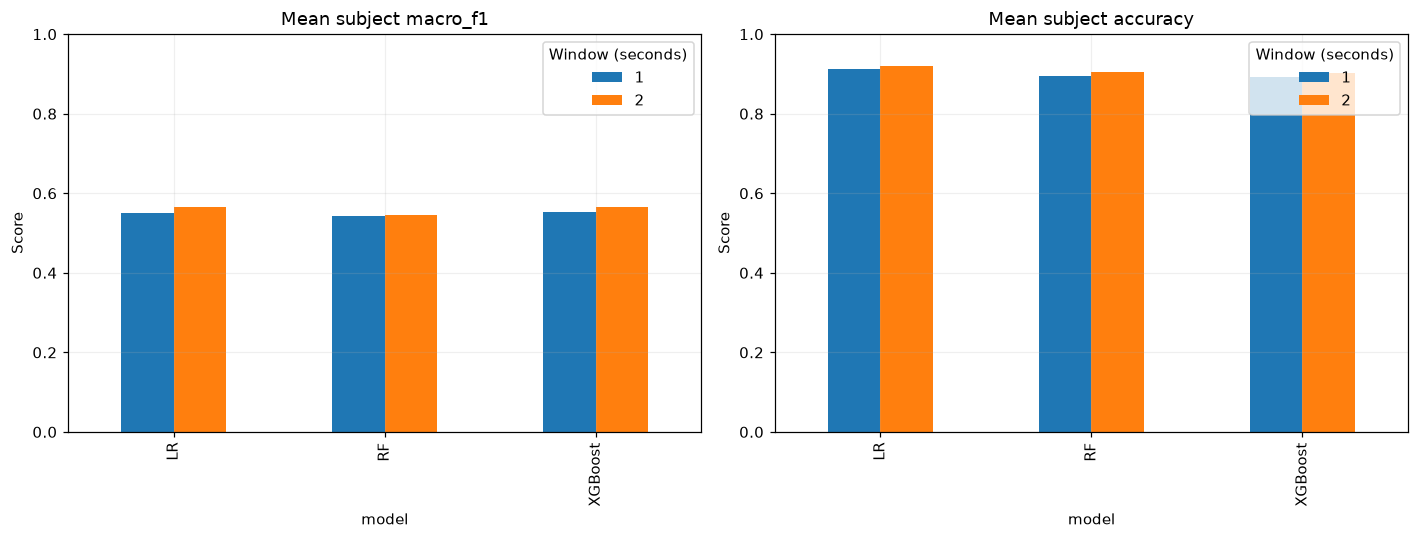

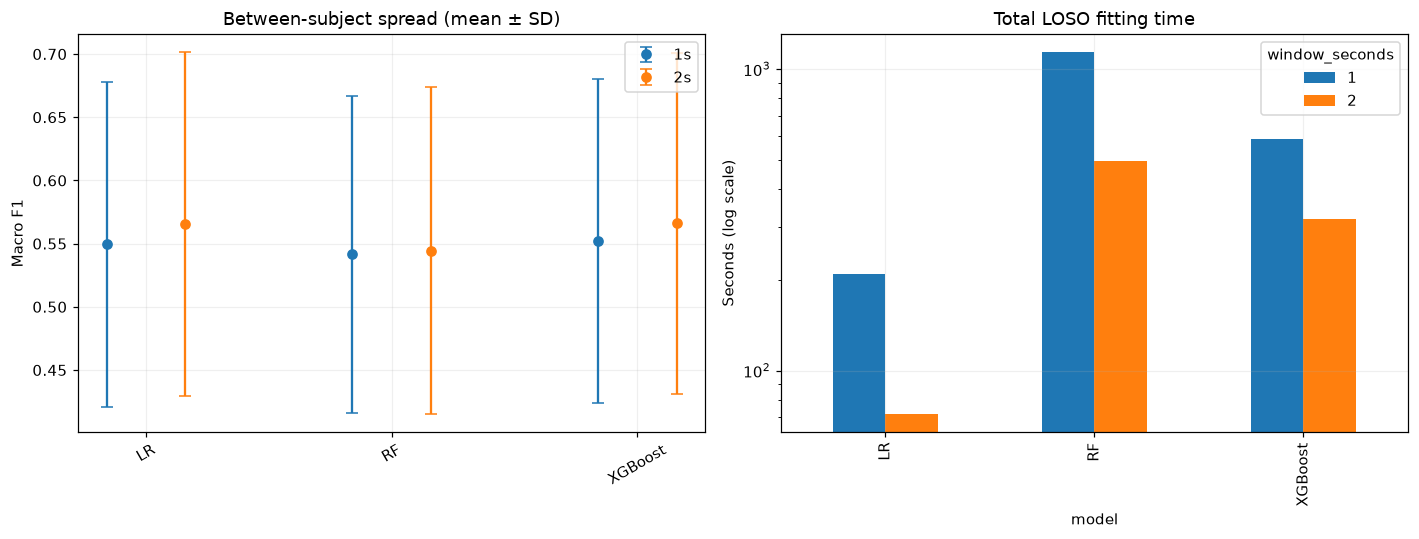

In [7]:
if baseline_models:
    fold_tables = []
    for name, estimator in baseline_models.items():
        for s in DURATIONS:
            X, meta = datasets[s]
            folds, _ = load_baseline(X[feature_columns(X)], meta, estimator, name, s)
            fold_tables.append(folds)
    scores = pd.concat(fold_tables, ignore_index=True)
    scores['predict_ms_per_window'] = 1000 * scores.predict_seconds / scores.test_windows
    scores.to_csv(OUT / 'all_baseline_folds.csv', index=False)
    summary = scores.groupby(['model', 'window_seconds']).agg(
        accuracy=('accuracy', 'mean'), macro_f1=('macro_f1', 'mean'),
        f1_std=('macro_f1', 'std'), present_class_macro_f1=('present_class_macro_f1', 'mean'),
        folds=('fold', 'count'), fit_seconds=('fit_seconds', 'sum'),
        predict_ms_per_window=('predict_ms_per_window', 'mean')).reset_index()
    summary.to_csv(OUT / 'baseline_summary.csv', index=False)
    display(summary.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for metric, ax in zip(['macro_f1', 'accuracy'], axes):
        summary.pivot(index='model', columns='window_seconds', values=metric).reindex(
            baseline_models).plot.bar(ax=ax)
        ax.set(title=f'Mean subject {metric}', ylabel='Score', ylim=(0, 1))
        ax.legend(title='Window (seconds)')
    finish_figure('baseline_scores')
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for s, offset in [(1, -.16), (2, .16)]:
        part = summary[summary.window_seconds == s].set_index('model').loc[list(baseline_models)]
        axes[0].errorbar(np.arange(len(part)) + offset, part.macro_f1,
                         yerr=part.f1_std, fmt='o', capsize=4, label=f'{s}s')
    axes[0].set_xticks(np.arange(len(baseline_models)), list(baseline_models), rotation=30)
    axes[0].set(title='Between-subject spread (mean ± SD)', ylabel='Macro F1')
    axes[0].legend()
    summary.pivot(index='model', columns='window_seconds', values='fit_seconds').reindex(
        baseline_models).plot.bar(ax=axes[1], logy=True)
    axes[1].set(title='Total LOSO fitting time', ylabel='Seconds (log scale)')
    finish_figure('baseline_spread_and_runtime')


## Paired duration differences

Positive values favor 2s. Subject-bootstrap 95% intervals are exploratory, without multiplicity correction.


,model,mean_delta_2s_minus_1s,ci_low,ci_high,subjects,subjects_favoring_2s,subjects_favoring_1s
0,LR,0.0159,0.0071,0.0252,21,15,6
1,RF,0.0029,-0.0055,0.0115,21,10,11
2,XGBoost,0.0139,0.0050,0.0226,21,17,4


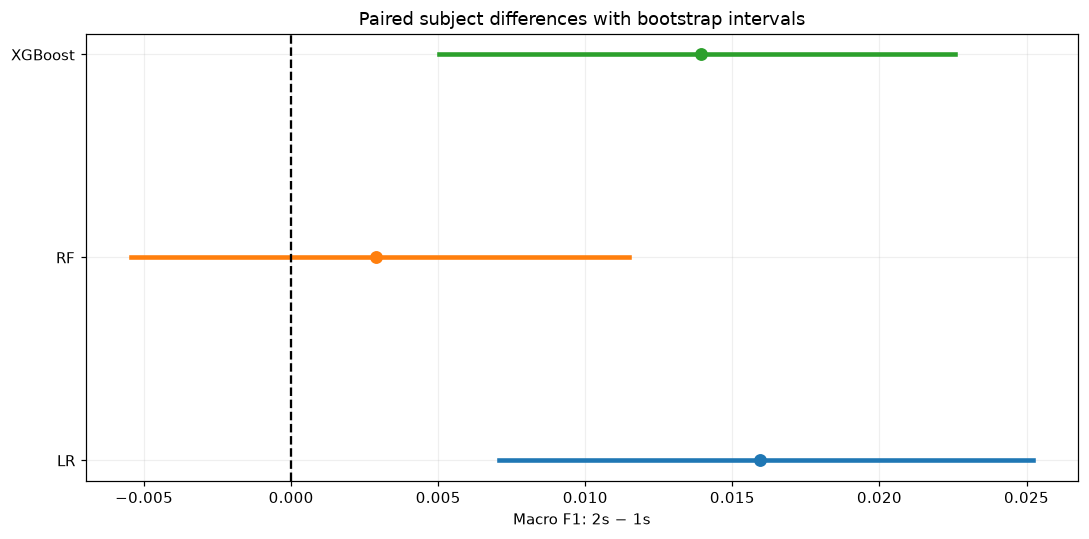

,model,window_seconds,accuracy,macro_f1,f1_std,present_class_macro_f1,folds,fit_seconds,predict_ms_per_window
5,XGBoost,2,0.902203,0.566157,0.135059,0.712003,21,319.238231,0.018019


Configuration with highest mean macro F1 shown above.


In [8]:
if baseline_models:
    paired = scores.pivot(index=['model', 'test_subjects'], columns='window_seconds',
                          values='macro_f1').rename(columns={1: 'f1_1s', 2: 'f1_2s'}).reset_index()
    assert not paired[['f1_1s', 'f1_2s']].isna().any().any()
    paired['delta_2s_minus_1s'] = paired.f1_2s - paired.f1_1s
    paired.to_csv(OUT / 'paired_subject_differences.csv', index=False)
    rng = np.random.default_rng(SEED)
    rows = []
    for name in baseline_models:
        values = paired.loc[paired.model == name, 'delta_2s_minus_1s'].to_numpy()
        boot = rng.choice(values, size=(10000, len(values)), replace=True).mean(axis=1)
        lo, hi = np.quantile(boot, [.025, .975])
        rows.append({'model': name, 'mean_delta_2s_minus_1s': values.mean(),
                     'ci_low': lo, 'ci_high': hi, 'subjects': len(values),
                     'subjects_favoring_2s': int((values > 0).sum()),
                     'subjects_favoring_1s': int((values < 0).sum())})
    differences = pd.DataFrame(rows)
    differences.to_csv(OUT / 'duration_difference_intervals.csv', index=False)
    display(differences.round(4))
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, row in differences.iterrows():
        ax.plot([row.ci_low, row.ci_high], [i, i], linewidth=3)
        ax.scatter(row.mean_delta_2s_minus_1s, i, s=55)
    ax.axvline(0, color='black', linestyle='--')
    ax.set_yticks(range(len(differences)), differences.model)
    ax.set(xlabel='Macro F1: 2s − 1s', title='Paired subject differences with bootstrap intervals')
    finish_figure('paired_duration_differences')
    display(summary.sort_values('macro_f1', ascending=False).head(1))
    print('Configuration with highest mean macro F1 shown above.')


## Evaluation outputs

Scores, predictions and figures: `results/window_comparison/`.
